# CS5100 Data Analysis Lab - Week 3: Binary classification algorithms

## Learning Outcomes

- Logistic Regression
- KNN classifiers
- ROC curves

For this lab, you need to import NumPy, Matplotlib, and Pandas

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
np.random.seed(1234)

## Binary classification
Try 2 binary-classification algorithms on the [Credit Card](https://moodle.royalholloway.ac.uk/mod/resource/view.php?id=1415055) dataset described and used in the textbook.
Credit card clients are described by 2 numerical attributes and a nominal feature. 
The goal is to predict the binary response variable called `default`.
Download the data from Moodle and print it.


In [13]:
file = "defaultISLPDataAnalysis202627.csv"
data = pd.read_csv(file,  sep=',', header=0)
print(data)

      Unnamed: 0 default student      balance        income
0              0      No      No   729.526495  44361.625074
1              1      No     Yes   817.180407  12106.134700
2              2      No      No  1073.549164  31767.138947
3              3      No      No   529.250605  35704.493935
4              4      No      No   785.655883  38463.495879
...          ...     ...     ...          ...           ...
9995        9995      No      No   711.555020  52992.378914
9996        9996      No      No   757.962918  19660.721768
9997        9997      No      No   845.411989  58636.156984
9998        9998      No      No  1569.009053  36669.112365
9999        9999      No     Yes   200.922183  16862.952321

[10000 rows x 5 columns]


Preprocess the data set. Select `default` as the target and the two quantitative features, `balance` and `income`, as predictors.

X_all.shape = (10000, 2), y_all.shape = (10000,)


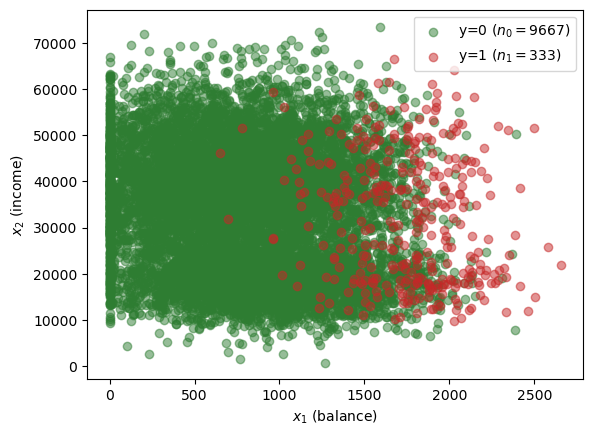

In [14]:
# create the labels
select = ['default']
y_all = 1*(data[select[0]].values == 'Yes')
select = ['balance', 'income']
x_names = select
X_all = data[select].to_numpy()
print(f'X_all.shape = {X_all.shape}, y_all.shape = {y_all.shape}')
negatives = np.where(y_all==0)[0]
positives = np.where(y_all==1)[0]

GREEN = "#2E7D32"   # green
BLUE = "#1565C0"   # blue
RED = "#C62828"
markers = ['.', '*']

plt.scatter(X_all[negatives, 0], X_all[negatives, 1], c=GREEN, alpha=.5, label=f'y=0 ($n_0={len(negatives)}$)')
plt.scatter(X_all[positives, 0], X_all[positives, 1], c=RED, alpha = .5, label=f'y=1 ($n_1={len(positives)}$)')
plt.xlabel(f'$x_1$ ({x_names[0]})')
plt.ylabel(f'$x_2$ ({x_names[1]})')

plt.legend()
plt.show()

Subsample the negative class and normalise the attributes

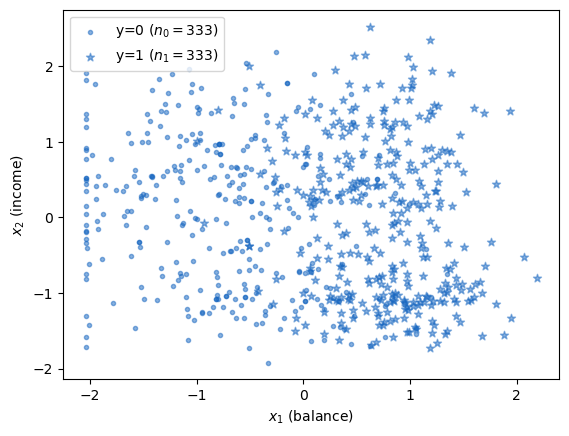

In [15]:
selection_negatives = np.random.choice(np.where(y_all==0)[0], size=len(np.where(y_all==1)[0]))
selection_positives = np.where(y_all==1)[0]
selection = np.concatenate((selection_negatives, selection_positives), axis=0)
X = X_all[selection]
y = y_all[selection]
X = (X - np.mean(X, axis=0))/(1e-4+np.std(X, axis=0))

positives = np.where(y==1)[0]
negatives = np.where(y==0)[0]

plt.scatter(X[negatives, 0], X[negatives, 1], c=BLUE, marker=markers[0], alpha=.5, label=f'y=0 ($n_0={len(negatives)}$)')
plt.scatter(X[positives, 0], X[positives, 1], c=BLUE, marker=markers[1], alpha = .5, label=f'y=1 ($n_1={len(positives)}$)')
plt.xlabel(f'$x_1$ ({x_names[0]})')
plt.ylabel(f'$x_2$ ({x_names[1]})')
plt.legend()
plt.show()
data_set = (X, y)

Reshuffle and split the data into a training, a validation and a test dataset. Plot the positives and negatives for all three data sets on the same axis using matplotlib.

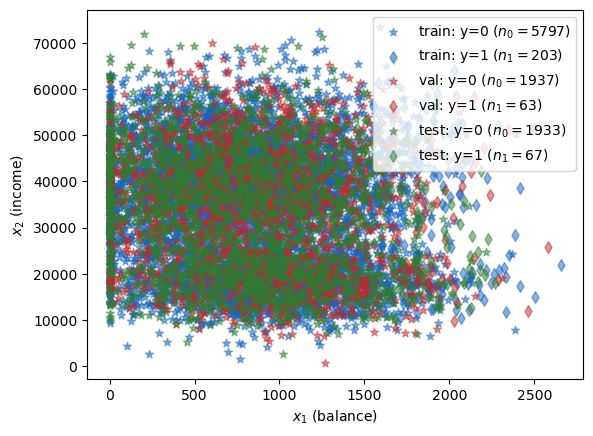

In [16]:
def split_dataset(D, ratio):
    X, y = D
    reshuffle = np.random.choice(len(X), len(X), replace=False)
    nratio = [int(np.floor(r * len(X))) for r in ratio]
    Xtrain, ytrain = [[s[i] for i in reshuffle[:nratio[0]]] for s in D]
    Xval, yval = [[s[i] for i in reshuffle[nratio[0]:nratio[0] + nratio[1]]] for s in D]
    Xtest, ytest = [[s[i] for i in reshuffle[nratio[0] + nratio[1]:]] for s in D]
    return (Xtrain, ytrain), (Xval, yval), (Xtest, ytest)

D = split_dataset((X_all, y_all), [.6, .2, .2])
train = [np.array(x) for x in D[0]]
validation = [np.array(x) for x in D[1]]
test = [np.array(x) for x in D[2]]

markers = ['*', 'd', 'o']
data_names = ['train', 'val', 'test']
colors = [BLUE, RED, GREEN]
for idata in range(len(data_names)):
    data_name = data_names[idata]
    X, y = [np.array(x) for x in D[idata]]
    negatives = np.where(y==0)[0]
    positives = np.where(y==1)[0]
    plt.scatter(X[negatives, 0], X[negatives, 1], marker=markers[0], 
                c=colors[idata], alpha=.5, label=f'{data_name}: y=0 ($n_0={len(negatives)}$)')
    plt.scatter(X[positives, 0], X[positives, 1], marker=markers[1], 
                c=colors[idata], alpha = .5, label=f'{data_name}: y=1 ($n_1={len(positives)}$)')
plt.xlabel(f'$x_1$ ({x_names[0]})')
plt.ylabel(f'$x_2$ ({x_names[1]})')
plt.legend()
plt.show()


### Logistic Regression

Define and train a logistic regression model using Gradient Descent.
Refactor the functions you wrote in Week 2 to minimise the training RSS of a linear regression model.
In this case, the objective is the negative log-likelihood of the training set, $D$, under the logistic regression model, 
$$
\ell(\beta) = - \sum_{(x, y) \in D} \log(y f(x) + (1-y)(1 - f(x))), \quad f(x) = \sigma(\beta_0 + \beta_1 x_1 + \beta_2 x_2) \approx {\rm Prob}(Y=1|X=x)$$
The gradient descent updates are defined as
$$ \beta^{(t+1)} \gets \beta^{(t)} - \eta \nabla \ell(\beta^{(t)})$$ 
$$ \nabla \ell(\beta) = - \sum_{(x, y) \in D} \frac{2y - 1}{y f(x) + (1-y)(1 - f(x))} \nabla f(x), \quad \nabla f(x) = \sigma(z)(1 - \sigma(z)) (1, x_1, x_2)^T, \quad z = \beta_0 + \beta_1 x_1 + \beta_2 x_2$$
Set the learning rate to $0.001$ and run the algorithm for 100 epochs from a random initial guess $\beta^{(0)} \sim {\rm Normal}(0, I_3)$. 

For all $t=0, \dots, T$, plot
- the normalised error rate, $\frac{{\rm ER}(\hat \beta^{(t)})}{{\rm ER}(\hat \beta^{(0)})}$, computed on the validation set and
- the normalised negative log-likelihood, $\frac{\ell(\hat \beta^{(t)})}{\ell(\hat \beta^{(0)})}$, computed on the training set.

In the title, report the model's test error rate.


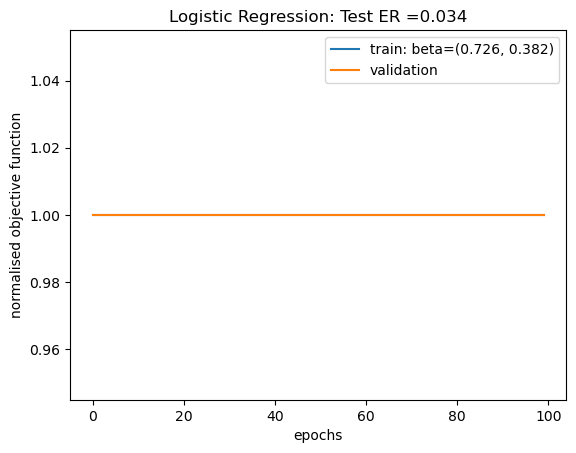

In [17]:
def z(X, beta):
    tildeX = np.concatenate((np.ones([len(X), 1]), X), axis = 1)
    return tildeX @ beta

def sigma(t):
    t = np.clip(t, -700, 700)
    return 1/(1 + np.exp(-t))

def f(X, beta):
    return sigma(z(X, beta))

def grad_f(X, beta):
    s = f(X, beta)
    tildeX = np.concatenate((np.ones([len(X), 1]), X), axis = 1)
    return (s * (1 - s)).reshape(-1, 1) * tildeX

def log_likelihood(train, beta):
    X, y = train
    p = np.clip(f(X, beta), 1e-12, 1 - 1e-12)
    return - np.sum(np.log(y * p + (1 - y) * (1 - p)))

def grad_log_likelihood(train, beta):
    X, y = train
    p = np.clip(f(X, beta), 1e-12, 1 - 1e-12)
    denominators = y * p + (1 - y) * (1 - p)
    nominators = (2 * y - 1)
    return - np.sum((nominators / denominators).reshape(-1, 1) * grad_f(X, beta), axis = 0)

def error_rate(y, haty):
    return np.mean(1 * (y != haty))

def prediction(prob):
    return np.argmax(prob, axis=1)

def evaluate_lr(data, beta):
    X, y = data
    proba = np.stack((1-f(X, beta), f(X, beta)), axis=1)
    return error_rate(y, prediction(proba))

T = 100
eta = 0.001
obj = []
obj_val = []
beta = np.random.randn(len(train[0][0]) + 1)
for t in range(T):
    obj.append(log_likelihood(train, beta))
    obj_val.append(evaluate_lr(validation, beta))
    grad = grad_log_likelihood(train, beta)
    beta  = beta - eta * grad

plt.plot([x/obj[0] for x in obj], label=f'train: beta=({beta[0]:.3f}, {beta[1]:.3f})')
plt.plot([x/obj_val[0] for x in obj_val], label=f'validation')
plt.xlabel('epochs')
plt.ylabel('normalised objective function')
plt.title(f'Logistic Regression: Test ER ={evaluate_lr(test, beta):.3f}')
plt.legend()
plt.show()


Define a $50 \times 50$ grid on the 2d input space $(X_1, X_2)$. Evaluate the model at each grid point to visualise the decision boundary and plot the test data on top of the grid.

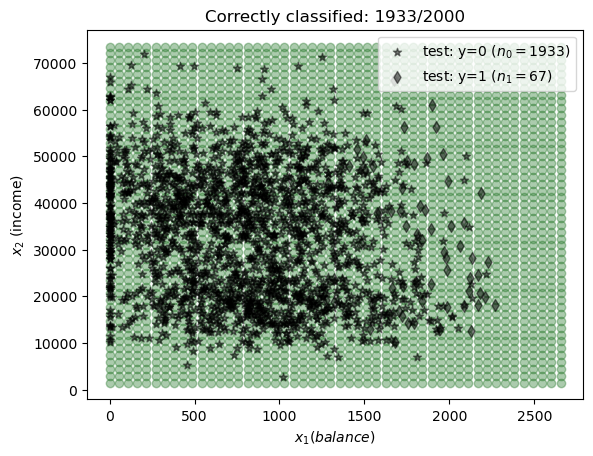

In [18]:
X, y = train
grid = [np.linspace(min(X[:, i]), max(X[:, i]), 50) for i in range(len(X[0]))]
for g1 in grid[0]:
    x_grid = np.stack((g1 * np.ones(len(grid[1])), grid[1]), axis = 1)
    proba = np.stack((1-f(x_grid, beta), f(x_grid, beta)), axis=1)
    haty = prediction(proba)
    s0 = grid[1][np.where(haty==0)]
    plt.scatter(g1 * np.ones(len(s0)), s0, color=GREEN, alpha=0.4)
    s1 = grid[1][np.where(haty==1)]
    plt.scatter(g1 * np.ones(len(s1)), s1, color=RED, alpha=0.4)

X, y = test
proba = np.stack((1-f(X, beta), f(X, beta)), axis=1)
negatives = np.where(y==0)[0]
positives = np.where(y==1)[0]
plt.scatter(X[negatives, 0], X[negatives, 1], marker=markers[0], 
                c='k', alpha=.5, label=f'test: y=0 ($n_0={len(negatives)}$)')
plt.scatter(X[positives, 0], X[positives, 1], marker=markers[1], 
                c='k', alpha = .5, label=f'test: y=1 ($n_1={len(positives)}$)')
plt.xlabel(f'$x_1 ({x_names[0]})$')
plt.ylabel(f'$x_2$ ({x_names[1]})')
plt.title(f'Correctly classified: {sum(y == prediction(proba))}/{len(y)}')
plt.legend()
plt.show()

## KNN

Define a $K=10$ Nearest-Neighbour binary classifier based on the squared Euclidean distance, ${\rm dist}(x, x')=\| x-x'\|^2=\sum_{j=1}^p (x_j-x_j')^2$.
In the regression setup, the algorithm computes the average labels in a $K$-element neighbour of the test object, ${\cal N}_x$.
For classification, you obtain the output by choosing the *most represented class* in ${\cal N}_x$ (*majority voting*).
This is equivalent to using a Bayes classifier based on the predicted conditional probability,
$$ p(x) = (1-p_1(x), p_1(x)), \quad p_1(x) = \frac1K\sum_{(x', y') \in {\cal N}_x} {\bf 1}(y' = 1) \approx {\rm Prob}(Y=1|X=x)$$


In [19]:
# define a KNN model
def dist(x, DX):
    return [np.linalg.norm(x - dx) **2 for dx in DX]
    
def nearest_neighbour(x, Dtrain, K):
    X, y = [np.array(x) for x in Dtrain]
    v = np.argsort(dist(x, X))[:K]
    return X[v], y[v]

def KNNclass(x, Dtrain, K):
    NX, Ny = nearest_neighbour(x, Dtrain, K)
    p = np.mean(Ny)
    return p

def evaluate_knn(data, Dtrain, K):
    X, y = data
    p1 = np.array([KNNclass(x, Dtrain, K) for x in X])
    proba = np.stack((1-p1, p1), axis=1)
    return error_rate(y, prediction(proba))

K = 10
print(f'KNN ER={evaluate_knn(test, train, K):.3f}')

KNN ER=0.033


Evaluate the model at each point of the $50 \times 50$ grid defined above and plot the test data on top of the grid.

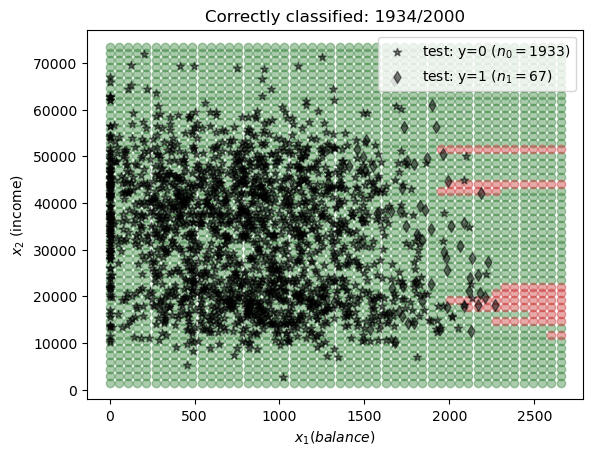

In [20]:
X, y = train 
grid = [np.linspace(min(X[:, i]), max(X[:, i]), 50) for i in range(len(X[0]))]
for g1 in grid[0]:
    x_grid = np.stack((g1 * np.ones(len(grid[1])), grid[1]), axis = 1)
    p1 = np.array([KNNclass(x, train, K) for x in x_grid])
    proba = np.stack((1-p1, p1), axis=1)
    haty = prediction(proba)
    s0 = grid[1][np.where(haty==0)]
    plt.scatter(g1 * np.ones(len(s0)), s0, color=GREEN, alpha=0.4)
    s1 = grid[1][np.where(haty==1)]
    plt.scatter(g1 * np.ones(len(s1)), s1, color=RED, alpha=0.4)

X, y = test
p1 = np.array([KNNclass(x, train, K) for x in X])
proba = np.stack((1-p1, p1), axis=1)
negatives = np.where(y==0)[0]
positives = np.where(y==1)[0]
plt.scatter(X[negatives, 0], X[negatives, 1], marker=markers[0], 
                c='k', alpha=.5, label=f'test: y=0 ($n_0={len(negatives)}$)')
plt.scatter(X[positives, 0], X[positives, 1], marker=markers[1], 
                c='k', alpha = .5, label=f'test: y=1 ($n_1={len(positives)}$)')
plt.xlabel(f'$x_1 ({x_names[0]})$')
plt.ylabel(f'$x_2$ ({x_names[1]})')
plt.title(f'Correctly classified: {sum(y == prediction(proba))}/{len(y)}')
plt.legend()
plt.show()

## Evaluating Binary Classification Algorithms with ROC curves

The [*Receiver Operating Characteristic (ROC) curve*](https://en.wikipedia.org/wiki/Receiver_operating_characteristic) is a popular method for evaluating and comparing binary classifiers.
The output of the binary classifiers used in this lab is interpreted as the conditional probability of default,
$$ f(x) \approx {\rm Prob}(Y = 1|X=x), \quad Y \in  \{ 0, 1\}, \quad x = ({\tt balance}, {\tt income})$$ 
Let $\xi \in [0, 1]$. The corresponding prediction on input $x$ is 
$$\hat y = \left\{ \begin{array}{ll}
{\tt yes} & {\rm if} \ f(x) \geq \xi\\
{\tt no} & {\rm otherwise}
\end{array}
\right.$$

Given the true test labels, $y_i$, and the corresponding $\xi$-level predictions, $\hat y_i$, compute the true/false positive/negative rates, 
$$TPR=\frac{TP}{P}, \quad  TNR=\frac{TN}{N}, \quad FPR=\frac{FP}{N}, \quad FNR=\frac{FN}{P}$$
where

1. true positives (TP): instances for which $\hat y_i = 1$ and $y_i = 1$,
2. true negatives (TN): instances for which $\hat y_i = 0$ and $y_i = 0$
3. false positives (FP): instances for which $\hat y_i = 1$ and $y_i = 0$, 
4. false negatives (FN): instances for which $\hat y_i = 0$ and $y_i = 1$.


${TPR}$ and ${TNR}$ are often called the *model sensitivity* and the *model specificity*. The *model accuracy* is 
$$ {\displaystyle \mathrm {ACC} ={\frac {\mathrm {TP} +\mathrm {TN} }{\mathrm {P} +\mathrm {N} }}={\frac {\mathrm {TP} +\mathrm {TN} }{\mathrm {TP} +\mathrm {TN} +\mathrm {FP} +\mathrm {FN} }}} $$

The ROC curve represents the model's sensitivity (TPR) for any possible False Positive Rate (FPR) and is obtained by computing TPR and FPR while varying the $\xi$-based *decision rule*. The Area Under the Curve (AUC) is the area under the ROC curve (a real number) and represents the overall performance of a binary classifier (the larger the better).

In this lab, you can use ``roc_curve`` from  ``sklearn.metrics`` to obtain the ROC curve and ``roc_auc_score`` to compute the AUC.
Both functions require the true labels and the predicted probabilities as inputs.

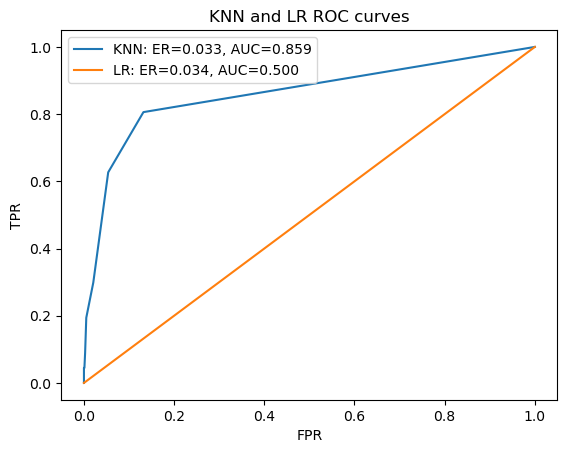

In [21]:
from sklearn.metrics import roc_curve, roc_auc_score

train = [np.array(x) for x in D[0]]
X, y = [np.array(x) for x in D[2]]

# KNN
pKNN = np.array([KNNclass(x, train, K) for x in X])
proba = np.stack((1-pKNN, pKNN), axis=1)
ER_KNN = error_rate(y, prediction(proba))
roc_KNN = roc_curve(y, pKNN)
auc_KNN = roc_auc_score(y, pKNN)

# LR
pLR = f(X, beta)
proba = np.stack((1-pLR, pLR), axis=1)
ER_LR = error_rate(y, prediction(proba))
roc_LR = roc_curve(y, pLR)
auc_LR = roc_auc_score(y, pLR)

plt.plot(roc_KNN[0], roc_KNN[1], label=f'KNN: ER={ER_KNN:.3f}, AUC={auc_KNN:.3f}')
plt.plot(roc_LR[0], roc_LR[1], label=f'LR: ER={ER_LR:.3f}, AUC={auc_LR:.3f}')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('KNN and LR ROC curves')
plt.legend()
plt.show()

## Exercises

You must complete the exercises below before attempting this week's Moodle quiz. Write your answers and your code in the dedicated cells below the questions.

### Q1

Write a Python function to encode nominal features using the dummy-variable approach. Redo the comparison above using the additional nominal feature ${\tt student} \in \{{\tt yes}, {\tt no}\}$. As the input space is 3-dimensional, you do not need to plot the model decision boundaries. 

Explain your results.

(10000, 3)
(10000,)


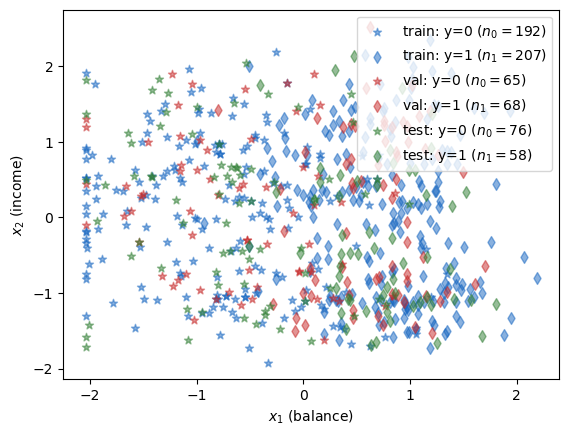

In [22]:
# write your code here

# nominal feature: categories rather than numbers
# dummy feature: student ∈ {yes, no} (1, 0)

def encode_student(data):
    result = data.copy()

    if not result["student"].isin(["No", "Yes"]).all():
        raise ValueError("student must contain only 'No' or 'Yes'")

    result["student_yes"] = (
        result["student"] == "Yes"
    ).astype(int)

    return result.drop(columns="student")


encoded_data = encode_student(data)

x_names = ["balance", "income", "student_yes"]
X_all = encoded_data[x_names].to_numpy(dtype=float)

y_all = (
    encoded_data["default"] == "Yes"
).to_numpy(dtype=int)

print(X_all.shape)
print(y_all.shape)

def split_dataset(D, ratio):
    X, y = D
    reshuffle = np.random.choice(len(X), len(X), replace=False)
    nratio = [int(np.floor(r * len(X))) for r in ratio]
    Xtrain, ytrain = [[s[i] for i in reshuffle[:nratio[0]]] for s in D]
    Xval, yval = [[s[i] for i in reshuffle[nratio[0]:nratio[0] + nratio[1]]] for s in D]
    Xtest, ytest = [[s[i] for i in reshuffle[nratio[0] + nratio[1]:]] for s in D]
    return (Xtrain, ytrain), (Xval, yval), (Xtest, ytest)

D = split_dataset(data_set, [.6, .2, .2])
train = [np.array(x) for x in D[0]]
validation = [np.array(x) for x in D[1]]
test = [np.array(x) for x in D[2]]

markers = ['*', 'd', 'o']
data_names = ['train', 'val', 'test']
colors = [BLUE, RED, GREEN]
for idata in range(len(data_names)):
    data_name = data_names[idata]
    X, y = [np.array(x) for x in D[idata]]
    negatives = np.where(y==0)[0]
    positives = np.where(y==1)[0]
    plt.scatter(X[negatives, 0], X[negatives, 1], marker=markers[0], 
                c=colors[idata], alpha=.5, label=f'{data_name}: y=0 ($n_0={len(negatives)}$)')
    plt.scatter(X[positives, 0], X[positives, 1], marker=markers[1], 
                c=colors[idata], alpha = .5, label=f'{data_name}: y=1 ($n_1={len(positives)}$)')
plt.xlabel(f'$x_1$ ({x_names[0]})')
plt.ylabel(f'$x_2$ ({x_names[1]})')
plt.legend()
plt.show()


-- write your answer here --

### Q2

To control possible overfitting, add an $L_2$ penalty to the log-likelihood objective you used to train the logistic regression model, 
$$ \ell(\hat \beta) \to \ell(\hat \beta) + \lambda \| \hat \beta\|^2, \quad \| \hat \beta\|^2 = \sum_{j=1}^p \hat \beta_j^2 $$
In KNN, you can tune the model flexibility by changing $K$.
Find the optimal values of $\lambda$ and $K$ on the Credit Card dataset used in this lab. **Hint**: Choose 10 possible values for each hyperparameter and measure the model performance on a validation set.   

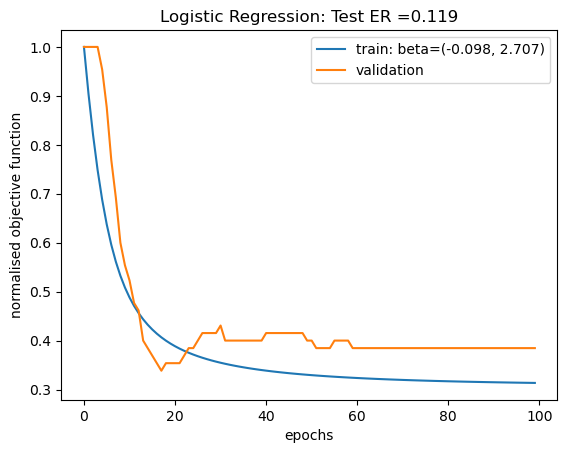

In [ ]:
# write your code here
# use logistic regression against 10 values separately, measure the performance and compare. do the same with

def z(X, beta):
    tildeX = np.concatenate((np.ones([len(X), 1]), X), axis = 1)
    return tildeX @ beta

def sigma(t):
    t = np.clip(t, -700, 700)
    return 1/(1 + np.exp(-t))

def f(X, beta):
    return sigma(z(X, beta))

def grad_f(X, beta):
    s = f(X, beta)
    tildeX = np.concatenate((np.ones([len(X), 1]), X), axis = 1)
    return (s * (1 - s)).reshape(-1, 1) * tildeX

def log_likelihood(train, beta):
    X, y = train
    p = np.clip(f(X, beta), 1e-12, 1 - 1e-12)
    
    return - np.sum(np.log(y * p + (1 - y) * (1 - p)))
    

def grad_log_likelihood(train, beta):
    X, y = train
    p = np.clip(f(X, beta), 1e-12, 1 - 1e-12)
    denominators = y * p + (1 - y) * (1 - p)
    nominators = (2 * y - 1)
    return - np.sum((nominators / denominators).reshape(-1, 1) * grad_f(X, beta), axis = 0)

def error_rate(y, haty):
    return np.mean(1 * (y != haty))

def prediction(prob):
    return np.argmax(prob, axis=1)

def evaluate_lr(data, beta):
    X, y = data
    proba = np.stack((1-f(X, beta), f(X, beta)), axis=1)
    return error_rate(y, prediction(proba))

T = 100
eta = 0.001
obj = []
obj_val = []
beta = np.random.randn(len(train[0][0]) + 1)
for t in range(T):
    obj.append(log_likelihood(train, beta))
    obj_val.append(evaluate_lr(validation, beta))
    grad = grad_log_likelihood(train, beta)
    beta  = beta - eta * grad

plt.plot([x/obj[0] for x in obj], label=f'train: beta=({beta[0]:.3f}, {beta[1]:.3f})')
plt.plot([x/obj_val[0] for x in obj_val], label=f'validation')
plt.xlabel('epochs')
plt.ylabel('normalised objective function')
plt.title(f'Logistic Regression: Test ER ={evaluate_lr(test, beta):.3f}')
plt.legend()
plt.show()

-- write your answer here -- 